In [ ]:
import numpy as np
import cupy as cp
import gc 
import matplotlib.pyplot as plt

from scipy.linalg import eigh
from scipy.special import comb 

from itertools import combinations 

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

%load_ext autoreload
%autoreload 2

import mylib_v2 as ml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
def build_matrices(N):


    if N % 2 == 0:
        Gamma_tensor = ml.Dirac_gen_GPU(N).astype(cp.complex64)

        Gamma_5 = Gamma_tensor[0]
        for i in range(N-1):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]

        diag = cp.diag(Gamma_5)

        if cp.allclose(diag.real, 0):
            mask = (diag.imag > 0)
        else:
            mask = (diag.real >0)

        
        s2 = cp.asarray(list(combinations(range(N), 2)))

        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]
        #matrices_2 = matrices_2[:, mask, :][:,:,mask]
    else:
        Gamma_tensor = ml.Dirac_gen_GPU(N-1).astype(cp.complex64)
        
        Gamma_5 = Gamma_tensor[0]
        for i in range(N-2):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]
        
        if (N-1) % 4 != 0:
            Gamma_5 = 1j*Gamma_5

        Gamma_5 = 2**(N/2)*Gamma_5 

        Gamma_5 = Gamma_5[None,:,:]
        Gamma_tensor = cp.concatenate((Gamma_tensor,Gamma_5), axis = 0)

        s2 = cp.asarray(list(combinations(range(N), 2)))
        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]
        

    return matrices_2

def compute_hamil(N, N_iterazioni, matrices_2):

    J = 1.0
    sigma = cp.sqrt(6)* J/(N)**(1.5)


    pairs = int(N*(N-1)/2)
    column_limit = np.zeros(pairs)

    for idx, (i,j) in enumerate(combinations(range(N),2)):
        column_limit[idx] = pairs - int((j+1)*(2*N-j-2)/2)

    column_limit = column_limit.astype(cp.int32)
    max_col = column_limit[0]
    column_limit = cp.asarray(column_limit)
    column_limit = column_limit[:-5]

    couplings_4 = cp.random.normal(loc=0.0, scale=sigma, size=(N_iterazioni, pairs-5, max_col), dtype=cp.float32)

    column_indices = cp.arange(max_col)
    mask = column_indices < column_limit[:, None]
    mask = mask[:,::-1]
    final_mat = couplings_4 * mask
    
    dim_matrice = matrices_2.shape[1]
    hamil = cp.zeros((N_iterazioni, dim_matrice, dim_matrice), dtype=matrices_2.dtype)

    m2_first = matrices_2[:(pairs-5)]
    m2_last = matrices_2[-max_col:]

    for n in range(N_iterazioni):
        tmp = cp.einsum('pc,cij->pij', final_mat[n], m2_last)
        
        hamil[n] = cp.einsum('cij,cjk->ik', tmp, m2_first)
    
    return hamil

In [12]:
N = 16
N_iterazioni = 1000
beta = 5
Ndots = 500

matrices_2 = build_matrices(N)
hamil = compute_hamil(N, N_iterazioni, matrices_2)

if N % 2 == 0:
    dim = int(2**(N/2))
else:
    dim = int(2**(N//2))

energies = cp.empty((N_iterazioni, dim), dtype=cp.float64)
Z_beta_samples = cp.empty((N_iterazioni), dtype=cp.float64)
t_values = cp.logspace(-1, 7, num=Ndots, base=10, dtype=cp.float64)
Z_beta_t_samples = cp.empty((N_iterazioni, t_values.shape[0]), dtype=cp.float64)
        
for i in range(N_iterazioni):
    energies[i] = cp.linalg.eigvalsh(hamil[i])
    Z_beta_samples[i] = cp.exp(-beta*energies[i]).sum()

Z_beta_t_samples = cp.exp(-(beta + 1j*t_values[cp.newaxis, :, cp.newaxis])*energies[:, cp.newaxis, :]).sum(axis=2)
Z_t_module_samples = Z_beta_t_samples.real**2 + Z_beta_t_samples.imag**2
Z_t_module = cp.mean(Z_t_module_samples, axis=0)

Z_beta = cp.mean(Z_beta_samples)

SFF = Z_t_module/(Z_beta**2)

t_values = t_values.get()
SFF = SFF.get()


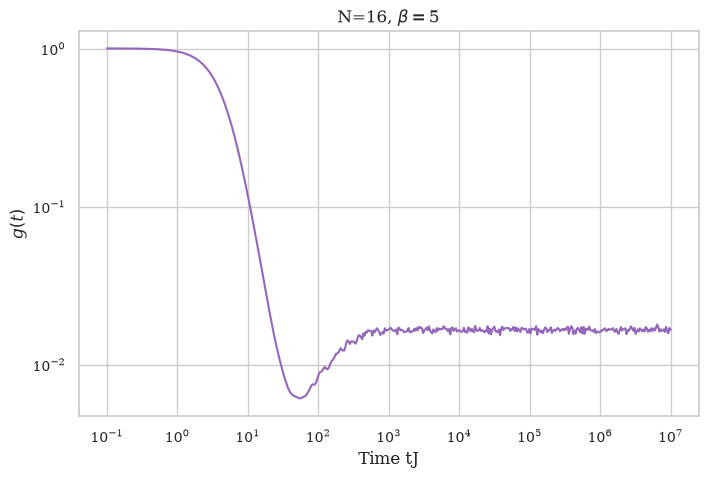

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(t_values, SFF, color="tab:purple")

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Time tJ")
plt.ylabel(fr'$g(t)$')
plt.title(fr'N={N}, $\beta =${beta}')


plt.show()

In [ ]:


# Svuotiamo i pool di CuPy e la RAM
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

# 2. Forza il Garbage Collector di Python a fare pulizia
gc.collect()

14420